# RTK: from metres to centimetres

This notebook runs the RTK engine on a rover and a base receiver a few metres apart:
differencing the carrier phases between receivers and satellites, filtering the float
solution, resolving the integer ambiguities with LAMBDA, and checking the fixed baseline
against the surveyed marker.

It runs on an hour of the IGS stations MATE (base) and MAT1 (rover) in Matera, Italy,
11 m apart, on 2021-12-26 when the environment variable `PYRX_CAPTURES` points at the
recordings directory (see `../README.md`), and otherwise on synthetic rover and base
observations generated from the package's own models, with a cycle slip planted halfway.
The committed outputs are from the stations.

The fundamentals behind it: [RTK](../../docs/fundamentals/09-rtk.md).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from support import (
    MAT1_MARKER,
    MATE_MARKER,
    RTK_BASE_WINDOW,
    RTK_SPAN,
    RTK_WINDOW,
    data_source,
    enu,
    figure,
    rnx2rtkp_rtk,
    scratch_dir,
    synthetic_rtk_epochs,
)

from pyrx.models import Station
from pyrx.plots import BAR_DETECTED, LINES, MUTED
from pyrx.rinex import read_rinex_header, read_rinex_nav, read_rinex_observations
from pyrx.rtk import Rtk, RtkOptions, pair_epochs, solve_rtk

out = scratch_dir("03-rtk")
signals = ("G1C", "G2W")
src = data_source()
if src is not None:
    rover = read_rinex_observations(src.mat1_obs, signals, RTK_WINDOW)
    base = read_rinex_observations(src.mate_obs, signals, RTK_BASE_WINDOW)
    ephs, _ = read_rinex_nav(src.brdc_mixed)
    hb, hr = read_rinex_header(src.mate_obs), read_rinex_header(src.mat1_obs)
    station, rover_delta, truth = Station(MATE_MARKER, hb.delta_enu), hr.delta_enu, MAT1_MARKER
else:
    rover, base, ephs, station, rover_delta, truth = synthetic_rtk_epochs()
baseline = np.linalg.norm(truth - station.marker)
print(f"{len(rover)} rover epochs, {len(base)} base epochs, baseline {baseline:.2f} m, "
      f"signals {', '.join(signals)}")

running on the recordings named by PYRX_CAPTURES


121 rover epochs, 121 base epochs, baseline 10.72 m, signals G1C, G2W


## 1. The pair

Every rover epoch is paired with the latest base epoch not after it, within 30 s. The
satellites both receivers see at once are the ones that can be differenced; the age is
how far the base epoch lags the rover's (zero here, both receivers log on the same
30 s grid).

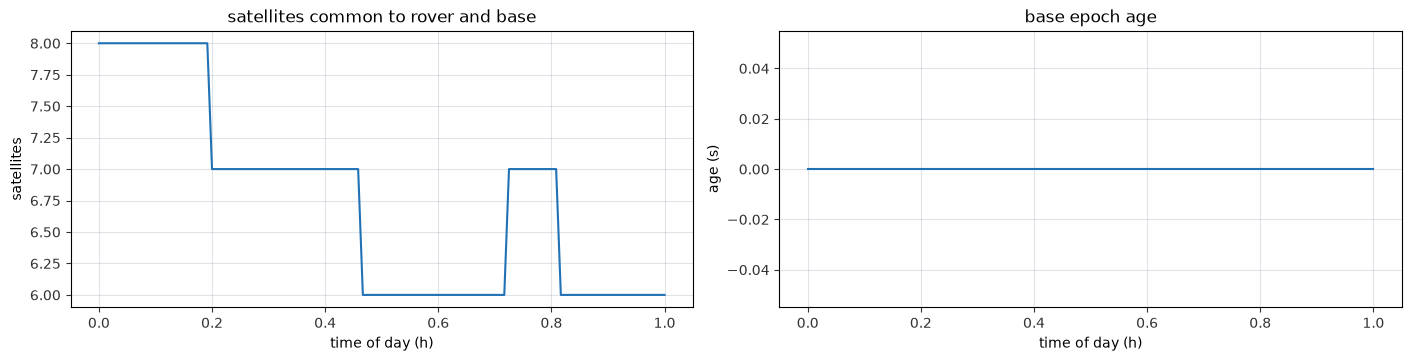

In [2]:
pairs = [(r, b) for r, b in pair_epochs(rover, base, 30.0) if b is not None]
hours = np.array([r.tow / 3600.0 for r, _ in pairs])
common = [len(set(r.sats) & set(b.sats)) for r, b in pairs]
age = [r.tow - b.tow for r, b in pairs]

fig, (ax_n, ax_a) = figure(1, 2, figsize=(14, 3.5))
ax_n.plot(hours, common, color=LINES[0])
ax_n.set_xlabel("time of day (h)")
ax_n.set_ylabel("satellites")
ax_n.set_title("satellites common to rover and base")
ax_a.plot(hours, age, color=LINES[0])
ax_a.set_xlabel("time of day (h)")
ax_a.set_ylabel("age (s)")
ax_a.set_title("base epoch age")
plt.show()

## 2. Differencing

Subtracting the base's carrier phase from the rover's for one satellite (a single
difference) cancels the satellite clock and, over a short baseline, the atmosphere.
Subtracting two satellites' single differences (a double difference) cancels the
receiver clocks too. The single differences below still wander with the difference of
the two receiver clocks; the double difference is a smooth line, the geometry of an 11 m
baseline turning under the satellites, plus an integer number of cycles. The traces have
their means removed. The synthetic rover's G03 L1 phase slips by three cycles halfway
through, and the double difference shows it as a step.

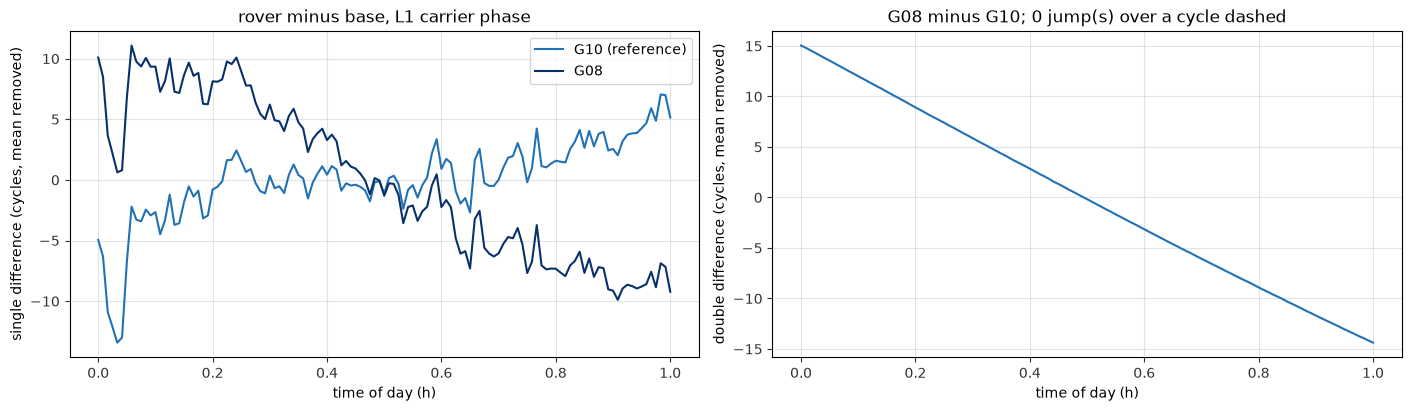

In [3]:
def phase(obs_list, sat, sig):
    j = obs_list[0].signals.index(sig)
    return np.array([o.carrier_phase[o.sats.index(sat), j] if sat in o.sats else np.nan for o in obs_list])

always = [s for s in pairs[0][0].sats if all(s in r.sats and s in b.sats for r, b in pairs)]
strength = {s: np.nanmean([r.cn0[r.sats.index(s), 0] for r, _ in pairs]) for s in always}
ref_sat, sat = sorted(always, key=lambda s: -strength[s])[:2]
if "G03" in always and src is None:
    sat = "G03"
rov, bas = [r for r, _ in pairs], [b for _, b in pairs]
sd_ref = phase(rov, ref_sat, "G1C") - phase(bas, ref_sat, "G1C")
sd_sat = phase(rov, sat, "G1C") - phase(bas, sat, "G1C")
dd = sd_sat - sd_ref
jumps = np.flatnonzero(np.abs(np.diff(dd)) > 1.0) + 1

fig, (ax_s, ax_d) = figure(1, 2, figsize=(14, 4))
ax_s.plot(hours, sd_ref - np.nanmean(sd_ref), color=LINES[0], label=f"{ref_sat} (reference)")
ax_s.plot(hours, sd_sat - np.nanmean(sd_sat), color=LINES[2], label=sat)
ax_s.set_xlabel("time of day (h)")
ax_s.set_ylabel("single difference (cycles, mean removed)")
ax_s.set_title("rover minus base, L1 carrier phase")
ax_s.legend()
ax_d.plot(hours, dd - np.nanmean(dd), color=LINES[0])
for k in jumps:
    ax_d.axvline(hours[k], color=BAR_DETECTED, linestyle="--")
ax_d.set_xlabel("time of day (h)")
ax_d.set_ylabel("double difference (cycles, mean removed)")
ax_d.set_title(f"{sat} minus {ref_sat}; {len(jumps)} jump(s) over a cycle dashed")
plt.show()

## 3. The float filter

A Kalman filter estimates the rover position and one real-valued ambiguity per
single-differenced satellite and signal from the double differences. The filter starts
from the single-point seed with a metre-level uncertainty, and both the error and the
band shrink as the ambiguities tighten; the band is the 3-D norm of the filter's position
standard deviation, an upper bound on each component. The second figure shows each
double-differenced ambiguity's distance from the integer the search settles on. Individual
float values can sit a fraction of a cycle off for the whole hour: they are strongly
correlated with each other and with the position, which is why the integers are searched
together in a decorrelated space rather than rounded one by one, and why the fixed
solution is right even so. A slip resets the satellite's state.

121 epochs solved in 1 s


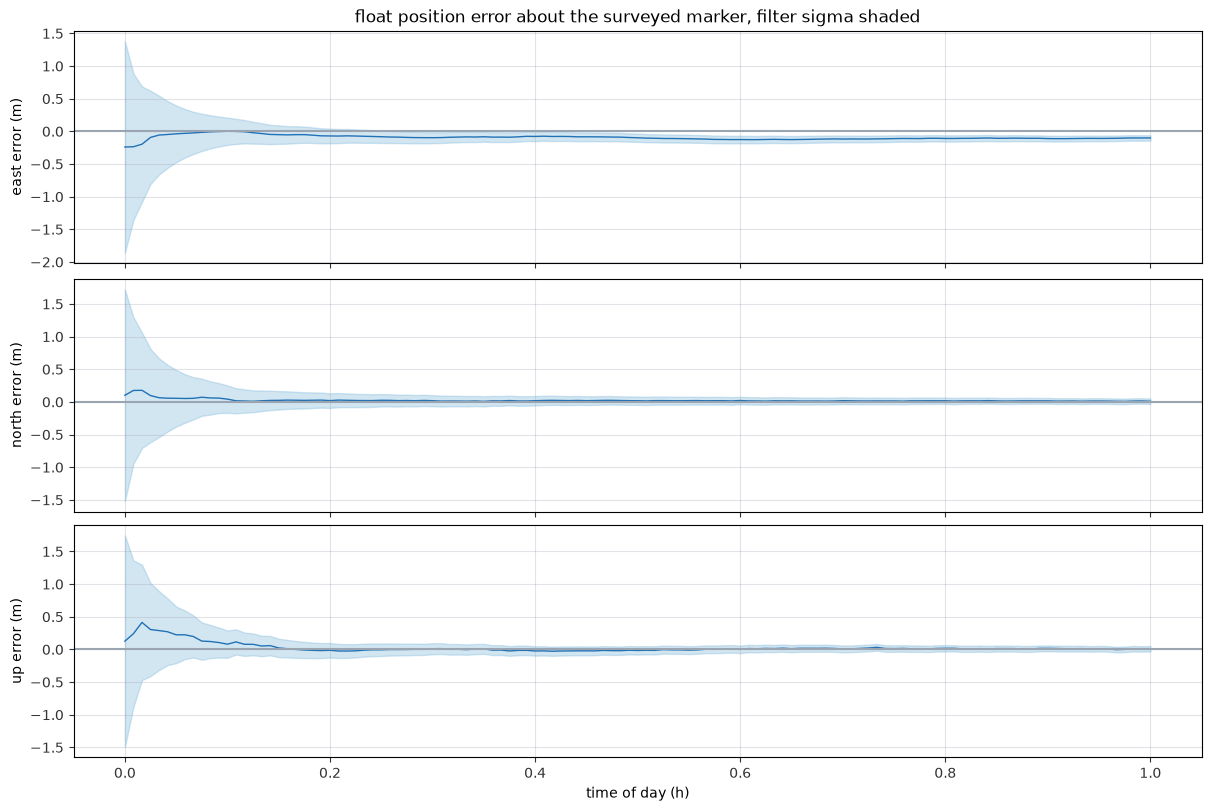

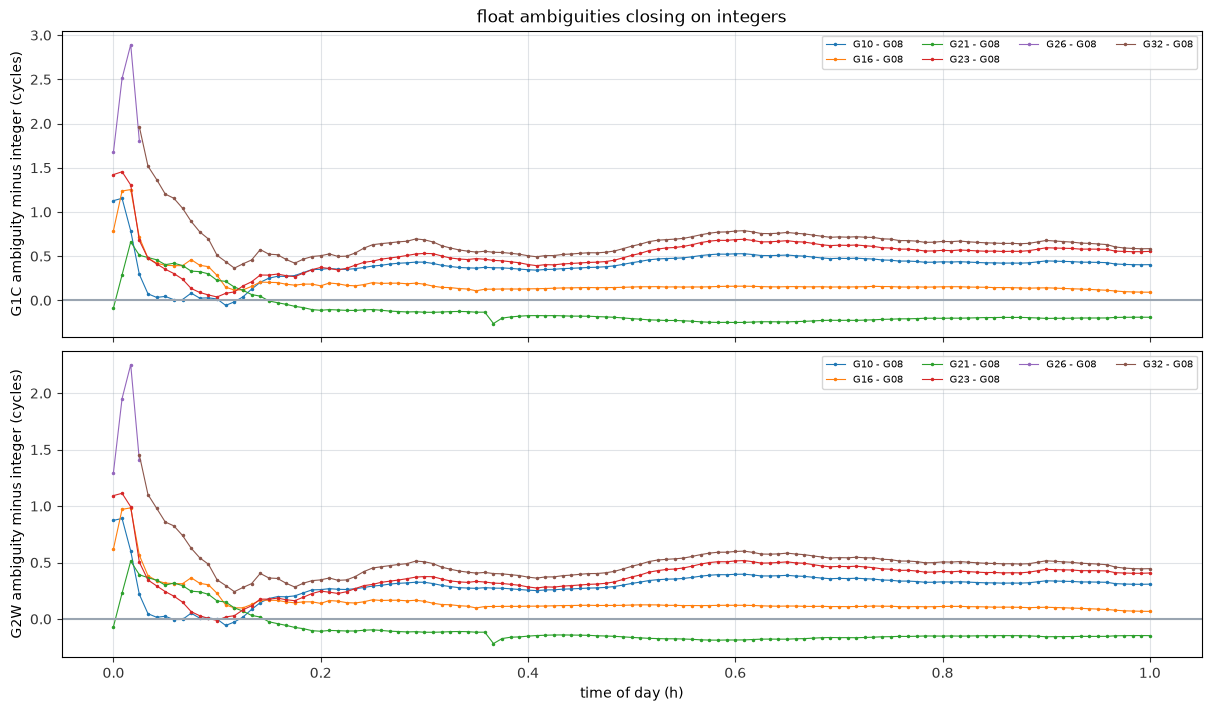

In [4]:
rtk = Rtk(ephs, station, rover_delta, RtkOptions())
t0 = time.perf_counter()
fixes = [f for f in (rtk.step(r, b) for r, b in pairs) if f is not None]
print(f"{len(fixes)} epochs solved in {time.perf_counter() - t0:.0f} s")
t = np.array([f.tow / 3600.0 for f in fixes])
float_err = enu(np.array([f.float_position for f in fixes]), truth)
sigma = np.array([np.linalg.norm(f.position_std) for f in fixes])

fig, axes = figure(3, 1, figsize=(12, 8), sharex=True)
for ax, j, name in zip(axes, range(3), ("east", "north", "up")):
    ax.fill_between(t, float_err[:, j] - sigma, float_err[:, j] + sigma, color=LINES[1], alpha=0.3)
    ax.plot(t, float_err[:, j], color=LINES[0], linewidth=1)
    ax.axhline(0, color=MUTED)
    ax.set_ylabel(f"{name} error (m)")
axes[0].set_title("float position error about the surveyed marker, filter sigma shaded")
axes[2].set_xlabel("time of day (h)")
plt.show()

residuals = {}
for f in fixes:
    for a in f.ambiguities:
        n = a.integer if a.integer is not None else round(a.value)
        residuals.setdefault((a.ref, a.sat, a.signal), []).append((f.tow / 3600.0, a.value - n))
fig, axes = figure(2, 1, figsize=(12, 7), sharex=True)
for ax, sig in zip(axes, signals):
    for (ref, s, g), points in sorted(residuals.items()):
        if g != sig:
            continue
        pts = np.array(points)
        ax.plot(pts[:, 0], pts[:, 1], ".-", markersize=3, linewidth=0.8, label=f"{s} - {ref}")
    ax.axhline(0, color=MUTED)
    ax.set_ylabel(f"{sig} ambiguity minus integer (cycles)")
    ax.legend(ncol=4, fontsize=7)
axes[0].set_title("float ambiguities closing on integers")
axes[1].set_xlabel("time of day (h)")
plt.show()

## 4. Resolution

LAMBDA searches the integer vectors nearest to the float ambiguities in the metric of
their covariance. The ratio of the second-best to the best candidate's squared distance
is the confidence measure: above the threshold of 3 the best set is accepted and the
position is corrected with it, giving the fixed solution. Its error about the surveyed
marker is at the centimetre level.

fixed 121 of 121 epochs; fixed 3-D error mean 0.68 cm, 95 % 1.35 cm, max 1.99 cm


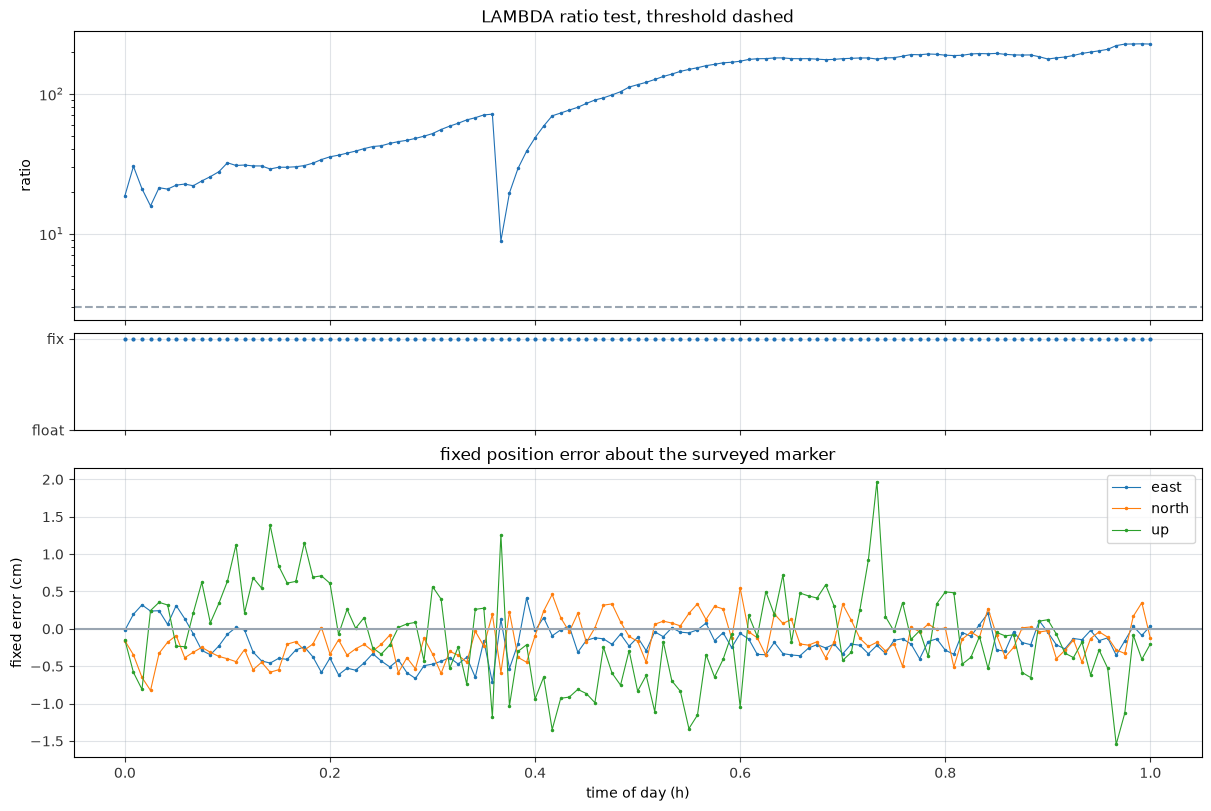

In [5]:
status = np.array([f.status == "fix" for f in fixes])
fixed_err = enu(np.array([f.position for f in fixes]), truth)
d3 = np.linalg.norm(fixed_err[status], axis=1)
print(f"fixed {status.sum()} of {len(fixes)} epochs; fixed 3-D error mean {d3.mean() * 100:.2f} cm, "
      f"95 % {np.percentile(d3, 95) * 100:.2f} cm, max {d3.max() * 100:.2f} cm")

fig, axes = figure(3, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1, 3]})
ax = axes[0]
ax.semilogy(t, [max(f.ratio, 0.1) for f in fixes], ".-", color=LINES[0], markersize=3, linewidth=0.8)
ax.axhline(rtk.opt.ratio_threshold, color=MUTED, linestyle="--")
ax.set_ylabel("ratio")
ax.set_title("LAMBDA ratio test, threshold dashed")
ax = axes[1]
ax.plot(t, status.astype(int), ".", color=LINES[0], markersize=4)
ax.set_yticks([0, 1])
ax.set_yticklabels(["float", "fix"])
ax = axes[2]
for j, name in enumerate(("east", "north", "up")):
    ax.plot(t[status], fixed_err[status, j] * 100, ".-", markersize=3, linewidth=0.8, label=name)
ax.axhline(0, color=MUTED)
ax.set_ylabel("fixed error (cm)")
ax.set_xlabel("time of day (h)")
ax.set_title("fixed position error about the surveyed marker")
ax.legend()
plt.show()

## 5. More signals

The same hour with GPS L5 and Galileo E1 and E5a added: more satellites in view, more
double differences per epoch, and a tighter fixed solution. Each system has its own
reference satellite, and the ambiguities are searched together.

121 epochs solved in 1 s
GPS L1/L2: fixed 121 of 121, mean error 0.68 cm; GPS+Galileo: fixed 121 of 121, mean error 0.48 cm


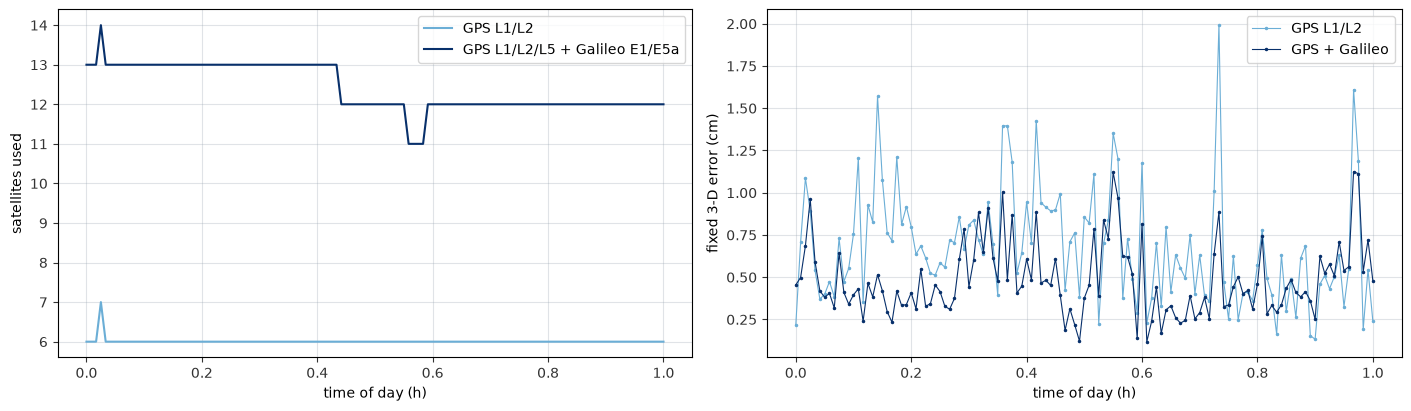

In [6]:
if src is None:
    print("synthetic data carries GPS L1 and L2 only")
else:
    more = ("G1C", "G2W", "G5Q", "E1C", "E5Q")
    rover5 = read_rinex_observations(src.mat1_obs, more, RTK_WINDOW)
    base5 = read_rinex_observations(src.mate_obs, more, RTK_BASE_WINDOW)
    t0 = time.perf_counter()
    fixes5 = solve_rtk(rover5, base5, ephs, station, rover_delta, RtkOptions())
    print(f"{len(fixes5)} epochs solved in {time.perf_counter() - t0:.0f} s")
    t5 = np.array([f.tow / 3600.0 for f in fixes5])
    status5 = np.array([f.status == "fix" for f in fixes5])
    err5 = np.linalg.norm(enu(np.array([f.position for f in fixes5]), truth), axis=1)
    print(f"GPS L1/L2: fixed {status.sum()} of {len(fixes)}, mean error {d3.mean() * 100:.2f} cm; "
          f"GPS+Galileo: fixed {status5.sum()} of {len(fixes5)}, mean error {err5[status5].mean() * 100:.2f} cm")
    fig, (ax_n, ax_e) = figure(1, 2, figsize=(14, 4))
    ax_n.plot(t, [f.ns for f in fixes], color=LINES[1], label="GPS L1/L2")
    ax_n.plot(t5, [f.ns for f in fixes5], color=LINES[2], label="GPS L1/L2/L5 + Galileo E1/E5a")
    ax_n.set_xlabel("time of day (h)")
    ax_n.set_ylabel("satellites used")
    ax_n.legend()
    ax_e.plot(t[status], d3 * 100, ".-", color=LINES[1], markersize=3, linewidth=0.8, label="GPS L1/L2")
    ax_e.plot(t5[status5], err5[status5] * 100, ".-", color=LINES[2], markersize=3, linewidth=0.8, label="GPS + Galileo")
    ax_e.set_xlabel("time of day (h)")
    ax_e.set_ylabel("fixed 3-D error (cm)")
    ax_e.legend()
    plt.show()

## 6. Against the reference

RTKLIB's `rnx2rtkp` in kinematic mode with the options this engine mirrors (continuous
ambiguity resolution, ratio threshold 3, 15° mask, broadcast ephemeris) gives an
independent fixed solution of the same hour. Its fixed epochs are overlaid on ours and
the per-epoch difference between the two engines is shown for the epochs both fixed.

RTKLIB fixed 121 of 121 epochs, pyrx 121 of 121; on the 121 epochs both fixed the positions differ by 0.08 mm mean, 0.14 mm max


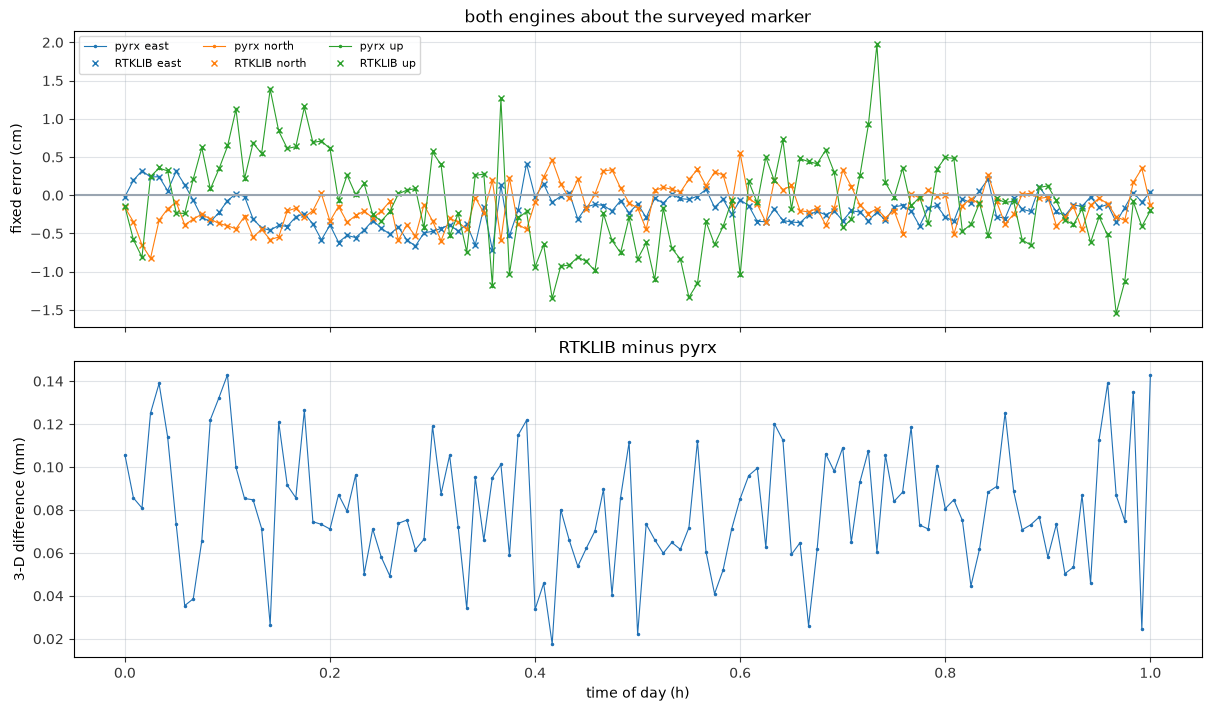

In [7]:
ref = None if src is None else rnx2rtkp_rtk(
    src.mat1_obs, src.mate_obs, src.brdc_mixed, out, MATE_MARKER, hb.delta_enu[2], hr.delta_enu[2], RTK_SPAN
)
if ref is None:
    print("no reference solution" if src is not None else "synthetic data: no reference solution")
else:
    ref_fixed = {k: v for k, v in ref.items() if v["q"] == 1}
    keys = [(f.week, round(f.tow, 1)) for f in fixes]
    both = [(i, ref_fixed[k]["xyz"]) for i, k in enumerate(keys) if status[i] and k in ref_fixed]
    idx = np.array([i for i, _ in both])
    ref_err = enu(np.array([xyz for _, xyz in both]), truth)
    diff = np.linalg.norm(ref_err - fixed_err[idx], axis=1)
    print(f"RTKLIB fixed {len(ref_fixed)} of {len(ref)} epochs, pyrx {status.sum()} of {len(fixes)}; "
          f"on the {len(both)} epochs both fixed the positions differ by {diff.mean() * 1e3:.2f} mm mean, "
          f"{diff.max() * 1e3:.2f} mm max")
    fig, (ax_e, ax_d) = figure(2, 1, figsize=(12, 7), sharex=True)
    for j, name in enumerate(("east", "north", "up")):
        line, = ax_e.plot(t[status], fixed_err[status, j] * 100, ".-", markersize=3, linewidth=0.8, label=f"pyrx {name}")
        ax_e.plot(t[idx], ref_err[:, j] * 100, "x", color=line.get_color(), markersize=4, label=f"RTKLIB {name}")
    ax_e.axhline(0, color=MUTED)
    ax_e.set_ylabel("fixed error (cm)")
    ax_e.set_title("both engines about the surveyed marker")
    ax_e.legend(ncol=3, fontsize=8)
    ax_d.plot(t[idx], diff * 1e3, ".-", color=LINES[0], markersize=3, linewidth=0.8)
    ax_d.set_xlabel("time of day (h)")
    ax_d.set_ylabel("3-D difference (mm)")
    ax_d.set_title("RTKLIB minus pyrx")
    plt.show()